# TLDC Week 5: Telugu Legal NLP Baselines

This notebook is a reproducible experiment scaffold for document classification, legal NER, section classification, and regional evaluation. It does not claim results from unreviewed examples. The current Week 4 pilot entries are pending review; expected split files may be empty.

## 1. Dataset Preparation and Splitting
Load Week 4 segmentation and legal entity annotations, require approved annotation and privacy status, validate labels and exact NER offsets, then create deterministic 70/15/15 splits grouped by `case_group_id`. Save JSONL partitions under `data/train`, `data/validation`, and `data/test`.

## 2. Exploratory Data Analysis
Inspect task, label, entity, section, language, and state distributions. Treat empty groups as a data-readiness result, not a model score.

## 3. Document Classification Baseline (TF-IDF + Classical ML)
Compare character n-gram TF-IDF with Logistic Regression and Linear SVM using training data for fitting and validation data for selection. Keep the test partition for final evaluation.

## 4. Legal Named Entity Recognition (NER) Baseline
Train only from exact character spans over the normalized text. Evaluate exact typed spans with precision, recall and F1, including per-entity-type results.

## 5. Transformer Model Experiments (IndicBERT, MuRIL, XLM-R)
Optional Hugging Face experiments are disabled by default. Verify model availability/licensing and install optional `transformers` and `torch` dependencies before enabling; never download weights or train without eligible data.

## 6. Legal Section Classification
Reuse the grouped partitions to classify annotated sections with classical models; compare with transformers only when the reviewed sample supports it.

## 7. Performance Evaluation and Error Analysis
Report accuracy, macro-F1, weighted-F1, per-class precision/recall and confusion matrices. Review errors by language, OCR quality and entity type, without treating accuracy as sufficient evidence.

## 8. Regional Generalisation Experiments
Compare Telangana and Andhra Pradesh slices or hold out districts only when each side has sufficient approved case groups and labels. Do not claim cross-state generalisation from a single-state sample.

All experiments use fixed seeds and record model/configuration details. A high score alone does not establish trustworthy or legally grounded predictions.

In [2]:
from collections import Counter
from pathlib import Path
import json
import sys

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Could not locate project root containing src/")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.training.dataset_builder import (
    build_week5_examples,
    split_by_case,
    write_jsonl_splits,
)

SEGMENTS_PATH = ROOT / "annotations/document_segmentation/segmented_documents.jsonl"
ENTITIES_PATH = ROOT / "annotations/legal_ner/legal_entities.jsonl"
REGISTER_PATH = ROOT / "metadata/document_register.csv"
DATA_ROOT = ROOT / "data"
RANDOM_SEED = 42

examples = build_week5_examples(SEGMENTS_PATH, REGISTER_PATH, ENTITIES_PATH)
if examples:
    partitions = split_by_case(examples, random_state=RANDOM_SEED)
else:
    partitions = {"train": [], "validation": [], "test": []}
write_jsonl_splits(partitions, DATA_ROOT)

print("Project root:", ROOT)
print("Eligible examples:", len(examples))
print("Task counts:", dict(Counter(row["task"] for row in examples)))
print("Split sizes:", {name: len(rows) for name, rows in partitions.items()})
if not examples:
    print("No eligible examples. Approve annotation/privacy review and add case_group_id before training.")

Project root: C:\Users\navee\Downloads\TLDC_Telugu_Legal_Corpus_Project_v0.1\TLDC_Telugu_Legal_Corpus_Project
Eligible examples: 0
Task counts: {}
Split sizes: {'train': 0, 'validation': 0, 'test': 0}
No eligible examples. Approve annotation/privacy review and add case_group_id before training.


task: {}
label: {}
language: {}
state: {}
Section types in source annotations: {'HEADER': 2, 'FACTS': 2, 'LEGAL_PROVISIONS': 2, 'JUDICIAL_OBSERVATION': 1, 'DECISION': 2, 'PETITIONER_ARGUMENT': 1}
Entity labels in source annotations: {'COURT': 2, 'CASE_NUMBER': 2, 'LEGAL_ACT': 1, 'SECTION': 2, 'DATE': 1}


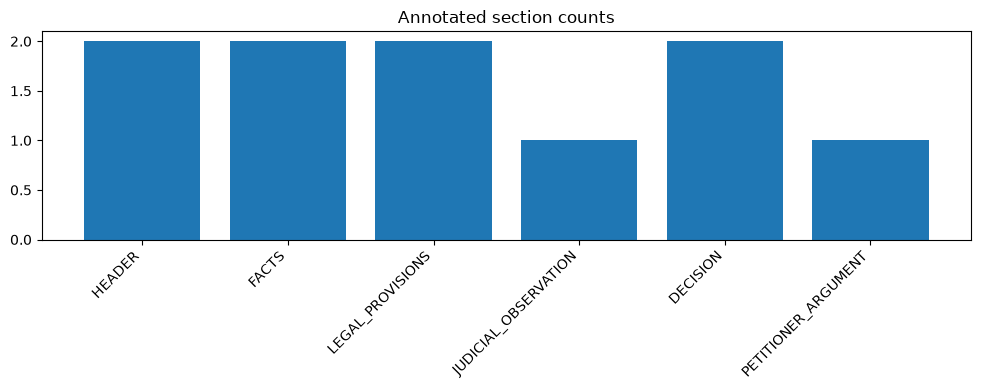

In [3]:
def read_jsonl(path):
    if not path.exists():
        return []
    with path.open(encoding="utf-8") as source:
        return [json.loads(line) for line in source if line.strip()]

train_rows = read_jsonl(DATA_ROOT / "train/tldc_train.jsonl")
validation_rows = read_jsonl(DATA_ROOT / "validation/tldc_validation.jsonl")
test_rows = read_jsonl(DATA_ROOT / "test/tldc_test.jsonl")
all_rows = train_rows + validation_rows + test_rows

for field in ("task", "label", "language", "state"):
    print(f"{field}:", dict(Counter(row.get(field, "UNKNOWN") for row in all_rows)))

segmentation_rows = read_jsonl(SEGMENTS_PATH)
section_counts = Counter(
    section.get("section_type", "UNKNOWN")
    for document in segmentation_rows
    for section in document.get("sections", [])
)
entity_rows = read_jsonl(ENTITIES_PATH)
entity_counts = Counter(row.get("label", "UNKNOWN") for row in entity_rows)
print("Section types in source annotations:", dict(section_counts))
print("Entity labels in source annotations:", dict(entity_counts))

# Optional plotting; text counts above remain available without matplotlib.
try:
    import matplotlib.pyplot as plt
    if section_counts:
        plt.figure(figsize=(10, 4))
        plt.bar(section_counts.keys(), section_counts.values())
        plt.xticks(rotation=45, ha="right")
        plt.title("Annotated section counts")
        plt.tight_layout()
        plt.show()
except ImportError:
    print("Install matplotlib to render charts; counts are available above.")

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC


def classification_rows(rows, task):
    return [row for row in rows if row.get("task") == task and row.get("text") and row.get("label")]


def compare_classical_models(task):
    training = classification_rows(train_rows, task)
    validation = classification_rows(validation_rows, task)
    if not training or not validation:
        print(f"Skip {task}: training or validation partition is empty.")
        return {}
    training_labels = {row["label"] for row in training}
    if len(training_labels) < 2:
        print(f"Skip {task}: at least two training labels are required.")
        return {}
    unseen = {row["label"] for row in validation} - training_labels
    if unseen:
        print(f"Skip {task}: validation labels absent from training: {sorted(unseen)}")
        return {}

    models = {
        "tfidf_logistic_regression": LogisticRegression(
            max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED
        ),
        "tfidf_linear_svm": LinearSVC(class_weight="balanced", random_state=RANDOM_SEED),
    }
    results = {}
    train_text = [row["text"] for row in training]
    validation_text = [row["text"] for row in validation]
    expected = [row["label"] for row in validation]
    for name, estimator in models.items():
        pipeline = Pipeline([
            ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(2, 5), max_features=100000)),
            ("classifier", estimator),
        ])
        pipeline.fit(train_text, [row["label"] for row in training])
        predicted = pipeline.predict(validation_text)
        results[name] = {
            "model": pipeline,
            "accuracy": accuracy_score(expected, predicted),
            "macro_f1": f1_score(expected, predicted, average="macro", zero_division=0),
            "weighted_f1": f1_score(expected, predicted, average="weighted", zero_division=0),
            "labels": sorted(set(expected) | set(predicted)),
            "confusion_matrix": confusion_matrix(expected, predicted).tolist(),
            "per_class": classification_report(expected, predicted, output_dict=True, zero_division=0),
            "predictions": predicted,
        }
        print(name, {key: results[name][key] for key in ("accuracy", "macro_f1", "weighted_f1")})
    return results


document_model_results = compare_classical_models("document_classification")

Skip document_classification: training or validation partition is empty.


In [5]:
from src.training.legal_ner_baseline import load_ner_rows, train_evaluate as evaluate_ner

training_ner = load_ner_rows(DATA_ROOT / "train/tldc_train.jsonl")
validation_ner = load_ner_rows(DATA_ROOT / "validation/tldc_validation.jsonl")
if training_ner and validation_ner:
    ner_validation_results = evaluate_ner(training_ner, validation_ner)
    print(json.dumps(ner_validation_results, ensure_ascii=False, indent=2))
else:
    print("Skip supervised NER: exact span annotations are required in non-empty train and validation splits.")

# Span offsets must be half-open offsets into each record's exact normalized `text` value.

Skip supervised NER: exact span annotations are required in non-empty train and validation splits.


In [6]:
MODEL_IDS = {
    "IndicBERT": "ai4bharat/IndicBERTv2-MLM-only",
    "MuRIL": "google/muril-base-cased",
    "XLM-RoBERTa": "FacebookAI/xlm-roberta-base",
}
SELECTED_TRANSFORMER = "XLM-RoBERTa"
RUN_TRANSFORMER_EXPERIMENT = False

if not RUN_TRANSFORMER_EXPERIMENT:
    print("Transformer training disabled. Verify checkpoint availability/licensing and set RUN_TRANSFORMER_EXPERIMENT=True only when reviewed data is sufficient.")
elif not classification_rows(train_rows, "document_classification") or not classification_rows(validation_rows, "document_classification"):
    print("Skip transformer training: non-empty train and validation document-classification data are required.")
else:
    try:
        import numpy as np
        from datasets import Dataset
        from transformers import (
            AutoModelForSequenceClassification,
            AutoTokenizer,
            Trainer,
            TrainingArguments,
            set_seed,
        )
    except ImportError as error:
        raise ImportError("Install optional dependencies with: pip install transformers datasets torch") from error

    transformer_train = classification_rows(train_rows, "document_classification")
    transformer_validation = classification_rows(validation_rows, "document_classification")
    label_names = sorted({row["label"] for row in transformer_train})
    label_to_id = {label: index for index, label in enumerate(label_names)}
    if len(label_names) < 2 or any(row["label"] not in label_to_id for row in transformer_validation):
        raise ValueError("Transformer development requires at least two training labels and validation labels seen in training")

    set_seed(RANDOM_SEED)
    checkpoint = MODEL_IDS[SELECTED_TRANSFORMER]
    tokenizer = AutoTokenizer.from_pretrained(checkpoint)
    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint,
        num_labels=len(label_names),
        label2id=label_to_id,
        id2label={index: label for label, index in label_to_id.items()},
    )

    def to_hf_dataset(rows):
        dataset = Dataset.from_list([
            {"text": row["text"], "labels": label_to_id[row["label"]]}
            for row in rows
        ])
        return dataset.map(lambda batch: tokenizer(batch["text"], truncation=True, max_length=512), batched=True)

    train_dataset = to_hf_dataset(transformer_train)
    validation_dataset = to_hf_dataset(transformer_validation)

    def transformer_metrics(prediction):
        logits, gold = prediction
        predicted = np.argmax(logits, axis=-1)
        return {
            "accuracy": accuracy_score(gold, predicted),
            "macro_f1": f1_score(gold, predicted, average="macro", zero_division=0),
            "weighted_f1": f1_score(gold, predicted, average="weighted", zero_division=0),
        }

    training_args = TrainingArguments(
        output_dir=str(ROOT / "models" / SELECTED_TRANSFORMER.lower().replace("-", "_")),
        learning_rate=2e-5,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        num_train_epochs=3,
        weight_decay=0.01,
        evaluation_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        seed=RANDOM_SEED,
        report_to="none",
    )
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=validation_dataset,
        compute_metrics=transformer_metrics,
    )
    trainer.train()
    transformer_validation_results = trainer.evaluate()
    transformer_validation_results

Transformer training disabled. Verify checkpoint availability/licensing and set RUN_TRANSFORMER_EXPERIMENT=True only when reviewed data is sufficient.


In [7]:
section_model_results = compare_classical_models("section_classification")
if section_model_results:
    print("Choose the section classifier by validation macro-F1; evaluate the test set only after selection.")
else:
    print("Section classification is pending eligible reviewed section examples in both train and validation partitions.")

Skip section_classification: training or validation partition is empty.
Section classification is pending eligible reviewed section examples in both train and validation partitions.


In [8]:
from sklearn.base import clone
from src.evaluation.regional_evaluation import evaluate_by_group

final_document_rows = classification_rows(train_rows + validation_rows, "document_classification")
final_test_rows = classification_rows(test_rows, "document_classification")
if document_model_results and final_document_rows and final_test_rows:
    selected_name = max(document_model_results, key=lambda name: document_model_results[name]["macro_f1"])
    selected_pipeline = clone(document_model_results[selected_name]["model"])
    selected_pipeline.fit(
        [row["text"] for row in final_document_rows],
        [row["label"] for row in final_document_rows],
    )
    expected_test = [row["label"] for row in final_test_rows]
    predicted_test = selected_pipeline.predict([row["text"] for row in final_test_rows])
    final_test_metrics = {
        "selected_model": selected_name,
        "accuracy": accuracy_score(expected_test, predicted_test),
        "macro_f1": f1_score(expected_test, predicted_test, average="macro", zero_division=0),
        "weighted_f1": f1_score(expected_test, predicted_test, average="weighted", zero_division=0),
        "per_class": classification_report(expected_test, predicted_test, output_dict=True, zero_division=0),
        "confusion_matrix": confusion_matrix(expected_test, predicted_test).tolist(),
        "by_state": evaluate_by_group(final_test_rows, predicted_test, "state"),
        "by_language": evaluate_by_group(final_test_rows, predicted_test, "language"),
    }
    error_rows = [
        {"document_id": row["document_id"], "state": row.get("state"), "language": row.get("language"),
         "expected": truth, "predicted": guess, "text_preview": row["text"][:240]}
        for row, truth, guess in zip(final_test_rows, expected_test, predicted_test)
        if truth != guess
    ]
    print(json.dumps({key: value for key, value in final_test_metrics.items() if key not in ("per_class", "confusion_matrix")}, ensure_ascii=False, indent=2))
    print("Misclassified test rows:", len(error_rows))
else:
    final_test_metrics = None
    error_rows = []
    print("Final test evaluation not run: select a validation model and provide eligible held-out test data first.")

final_train_ner = load_ner_rows(DATA_ROOT / "train/tldc_train.jsonl") + load_ner_rows(DATA_ROOT / "validation/tldc_validation.jsonl")
final_test_ner = load_ner_rows(DATA_ROOT / "test/tldc_test.jsonl")
if final_train_ner and final_test_ner:
    final_ner_metrics = evaluate_ner(final_train_ner, final_test_ner)
    print("Final exact-span NER metrics:", json.dumps(final_ner_metrics, ensure_ascii=False, indent=2))
else:
    final_ner_metrics = None
    print("Final NER evaluation not run: reviewed exact-span train and test data are required.")

Final test evaluation not run: select a validation model and provide eligible held-out test data first.
Final NER evaluation not run: reviewed exact-span train and test data are required.


In [9]:
from sklearn.base import clone


def run_regional_transfer(rows, group_field, train_groups, held_out_group):
    if not isinstance(train_groups, (set, list, tuple)):
        train_groups = {train_groups}
    training = [row for row in rows if row.get(group_field) in train_groups]
    held_out = [row for row in rows if row.get(group_field) == held_out_group]
    if not training or not held_out:
        return {"status": "skipped", "reason": "empty regional partition"}
    training_groups = {row["case_group_id"] for row in training}
    held_out_groups = {row["case_group_id"] for row in held_out}
    if training_groups & held_out_groups:
        return {"status": "skipped", "reason": "case groups overlap between regions"}
    if len({row["label"] for row in training}) < 2:
        return {"status": "skipped", "reason": "training region has fewer than two labels"}

    template = Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(2, 5), max_features=100000)),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)),
    ])
    regional_model = clone(template)
    regional_model.fit([row["text"] for row in training], [row["label"] for row in training])
    predictions = regional_model.predict([row["text"] for row in held_out])
    expected = [row["label"] for row in held_out]
    return {
        "status": "evaluated",
        "count": len(held_out),
        "accuracy": accuracy_score(expected, predictions),
        "macro_f1": f1_score(expected, predictions, average="macro", zero_division=0),
        "weighted_f1": f1_score(expected, predictions, average="weighted", zero_division=0),
        "by_language": evaluate_by_group(held_out, predictions, "language"),
    }


regional_documents = [row for row in all_rows if row.get("task") == "document_classification"]
state_names = sorted({row.get("state") for row in regional_documents if row.get("state")})
if len(state_names) >= 2:
    for training_state, held_out_state in ((state_names[0], state_names[1]), (state_names[1], state_names[0])):
        print(f"Train {training_state} -> test {held_out_state}:", run_regional_transfer(regional_documents, "state", {training_state}, held_out_state))
else:
    print("Cross-state experiment skipped: reviewed document examples from two states are required.")

district_names = sorted({row.get("district") for row in regional_documents if row.get("district")})
if len(district_names) >= 2:
    held_out_district = district_names[-1]
    training_districts = set(district_names[:-1])
    print(f"Train districts {sorted(training_districts)} -> held-out district {held_out_district}:")
    print(run_regional_transfer(regional_documents, "district", training_districts, held_out_district))
else:
    print("District experiment skipped: at least two reviewed districts are required.")

Cross-state experiment skipped: reviewed document examples from two states are required.
District experiment skipped: at least two reviewed districts are required.
